In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Set random seed
torch.manual_seed(42)

# Select GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert image pixels to tensors in the range [0, 1]
transform = transforms.ToTensor()

# Download MNIST training and testing datasets
train_dataset = datasets.MNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Using device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 62.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.48MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.01MB/s]

Training samples: 60000
Testing samples: 10000


In [ ]:
# Define a Convolutional Neural Network
class MNISTCNN(nn.Module):
    def __init__(self):
        super(MNISTCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)

        x = F.relu(self.conv2(x))
        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Initialize the model
model = MNISTCNN().to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Train the model
epochs = 2

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {avg_loss:.4f}"
    )


# Evaluate the original model
def evaluate_clean(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


clean_accuracy = evaluate_clean(model, test_loader)

print(f"Clean test accuracy: {clean_accuracy:.2f}%")

Epoch [1/2], Loss: 0.2549
Epoch [2/2], Loss: 0.0613
Clean test accuracy: 98.71%


In [ ]:
# FGSM attack function
def fgsm_attack(images, epsilon, data_grad):
    # Find the sign of the gradient
    gradient_sign = data_grad.sign()

    # Add the calculated perturbation
    perturbed_images = images + epsilon * gradient_sign

    # Keep all pixel values within [0, 1]
    perturbed_images = torch.clamp(
        perturbed_images,
        min=0,
        max=1
    )

    return perturbed_images


# Test the model against an FGSM attack
def evaluate_fgsm(model, loader, epsilon):
    model.eval()

    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Calculate gradients with respect to the input image
        images.requires_grad_(True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        model.zero_grad(set_to_none=True)
        loss.backward()

        # Extract gradients of the loss with respect to pixels
        data_grad = images.grad.detach()

        # Generate adversarial images
        adversarial_images = fgsm_attack(
            images,
            epsilon,
            data_grad
        )

        # Evaluate predictions on adversarial images
        with torch.no_grad():
            adversarial_outputs = model(adversarial_images)
            predictions = adversarial_outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100 * correct / total


# Experiment with different perturbation strengths
epsilons = [0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
accuracies = []

for eps in epsilons:
    accuracy = evaluate_fgsm(model, test_loader, eps)
    accuracies.append(accuracy)

    print(
        f"Epsilon: {eps:.2f} | "
        f"Adversarial Test Accuracy: {accuracy:.2f}%"
    )

Epsilon: 0.00 | Adversarial Test Accuracy: 98.71%
Epsilon: 0.05 | Adversarial Test Accuracy: 95.69%
Epsilon: 0.10 | Adversarial Test Accuracy: 88.17%
Epsilon: 0.15 | Adversarial Test Accuracy: 70.24%
Epsilon: 0.20 | Adversarial Test Accuracy: 43.41%
Epsilon: 0.25 | Adversarial Test Accuracy: 18.18%
Epsilon: 0.30 | Adversarial Test Accuracy: 4.97%


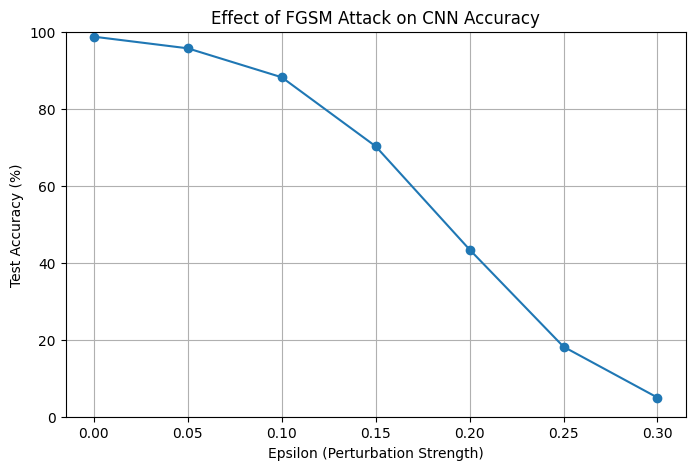

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    epsilons,
    accuracies,
    marker="o"
)

plt.title("Effect of FGSM Attack on CNN Accuracy")
plt.xlabel("Epsilon (Perturbation Strength)")
plt.ylabel("Test Accuracy (%)")

plt.xticks(epsilons)
plt.ylim(0, 100)
plt.grid(True)

plt.show()

True label: 7
Original prediction: 7
Adversarial prediction: 3


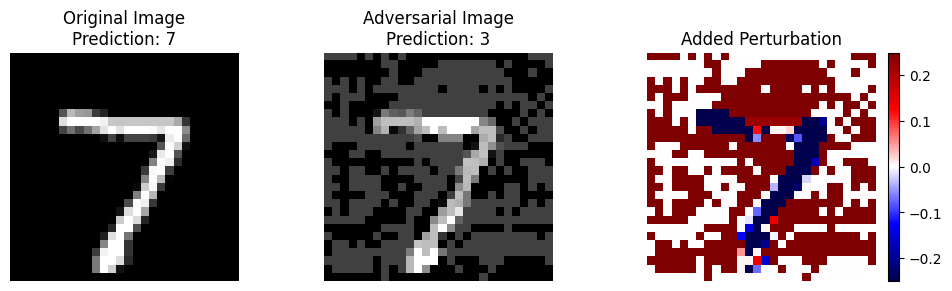

In [ ]:
def find_example(epsilon=0.25):
    model.eval()
    fallback = None

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        images.requires_grad_(True)

        outputs = model(images)
        clean_predictions = outputs.argmax(dim=1)

        loss = criterion(outputs, labels)

        model.zero_grad(set_to_none=True)
        loss.backward()

        data_grad = images.grad.detach()

        adversarial_images = fgsm_attack(
            images,
            epsilon,
            data_grad
        )

        with torch.no_grad():
            adversarial_outputs = model(adversarial_images)
            adversarial_predictions = adversarial_outputs.argmax(dim=1)

        # Consider images that were initially classified correctly
        correct_mask = clean_predictions.eq(labels)

        # Save a fallback example in case no successful attack is found
        if fallback is None and correct_mask.any():
            idx = correct_mask.nonzero(as_tuple=True)[0][0].item()

            fallback = (
                images[idx].detach().cpu(),
                adversarial_images[idx].detach().cpu(),
                labels[idx].item(),
                clean_predictions[idx].item(),
                adversarial_predictions[idx].item()
            )

        # Prefer an example that becomes incorrectly classified
        fooled_mask = correct_mask & adversarial_predictions.ne(labels)

        if fooled_mask.any():
            idx = fooled_mask.nonzero(as_tuple=True)[0][0].item()

            return (
                images[idx].detach().cpu(),
                adversarial_images[idx].detach().cpu(),
                labels[idx].item(),
                clean_predictions[idx].item(),
                adversarial_predictions[idx].item()
            )

    return fallback


epsilon_show = 0.25
example = find_example(epsilon_show)

if example is None:
    print("No correctly classified example was found.")
else:
    original, adversarial, true_label, clean_pred, adv_pred = example

    print("True label:", true_label)
    print("Original prediction:", clean_pred)
    print("Adversarial prediction:", adv_pred)

    perturbation = adversarial - original

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))

    axes[0].imshow(original.squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"Original Image\nPrediction: {clean_pred}")

    axes[1].imshow(adversarial.squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1].set_title(f"Adversarial Image\nPrediction: {adv_pred}")

    im = axes[2].imshow(
        perturbation.squeeze(),
        cmap="seismic",
        vmin=-epsilon_show,
        vmax=epsilon_show
    )
    axes[2].set_title("Added Perturbation")
    fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()